# 3 · Real data: day-ahead electricity demand, 2019-2025

**The model:** for 12 large US grid operators, predict each hour of tomorrow's electricity demand from
the calendar and recent demand (yesterday, two days ago, last week). Trained on 2019, then used week by
week through 2025. Actual demand arrives the next day, so the true answers come back within a week.
Errors are a fraction of the operator's typical load (0.05 = 5%). No weather data: a deliberately
simple model, which is fine for comparing *retraining rules*.

**What changed in the real world:** COVID lockdowns (March 2020) reshaped daily demand; Winter Storms Uri
(Feb 2021) and Elliott (Dec 2022) were extreme; Texas (ERCOT) and Florida demand grew fast.

**Honest setup:** there is no drift-free stretch to calibrate on and no known "right" retrain date. So
each trigger's threshold is **chosen on 2020-2021** and **scored once on 2022-2025**.

In [1]:
%matplotlib inline
import os, json, warnings
os.chdir('..')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from retrain import plot
plot.style()
pd.set_option('display.width', 160)
LABELS = {'never': 'never retrain', 'schedule': 'every 10 batches', 'psi': 'input drift: PSI',
          'psi_rule': 'input drift: PSI > 0.2 rule', 'ks': 'input drift: KS test', 'c2st': 'input drift: classifier test',
          'pred_psi': 'prediction drift: PSI', 'error': 'error ratio', 'page_hinkley': 'Page-Hinkley (error)',
          'psi_error': 'input flag + error confirms', 'error_cp': 'error ratio + change point',
          'page_hinkley_cp': 'Page-Hinkley + change point', 'error_cpw': 'error ratio + weighted window',
          'page_hinkley_cpw': 'Page-Hinkley + weighted window', 'oracle': 'oracle (knows the change)'}

from retrain import realdata, eia, backtest
rows = json.load(open('results/real_runs.json'))
t = realdata.table(rows)
never = {r['ba']: r for r in rows if r['trigger'] == 'never'}

In [2]:
yr = pd.DataFrame({ba: pd.Series(r['mae'], index=pd.to_datetime(r['weeks'])).groupby(lambda w: w.year).mean()
                   for ba, r in never.items()}).T
(yr * 100).round(1).rename(columns=lambda c: f'{c} error %')

,2020 error %,2021 error %,2022 error %,2023 error %,2024 error %,2025 error %
ERCO,5.2,5.4,6.7,7.0,8.4,9.3
PJM,4.1,4.4,4.8,3.9,4.6,4.7
CISO,3.7,3.3,3.7,3.7,4.1,3.8
MISO,3.2,3.6,3.9,3.2,3.7,3.5
SWPP,4.3,4.5,5.0,4.4,4.9,5.4
NYIS,4.6,5.0,5.0,4.5,4.8,5.2
ISNE,5.9,6.2,6.0,6.0,6.4,7.2
SOCO,5.5,5.2,5.7,5.1,5.5,5.7
TVA,5.8,6.1,7.1,5.8,6.5,6.9
BPAT,3.4,3.6,3.9,3.5,3.6,3.6


Without retraining, most operators drift slowly. **ERCOT's error goes from 5% to 9%**: demand grows past
anything seen in 2019, and tree models cannot predict values beyond their training range.

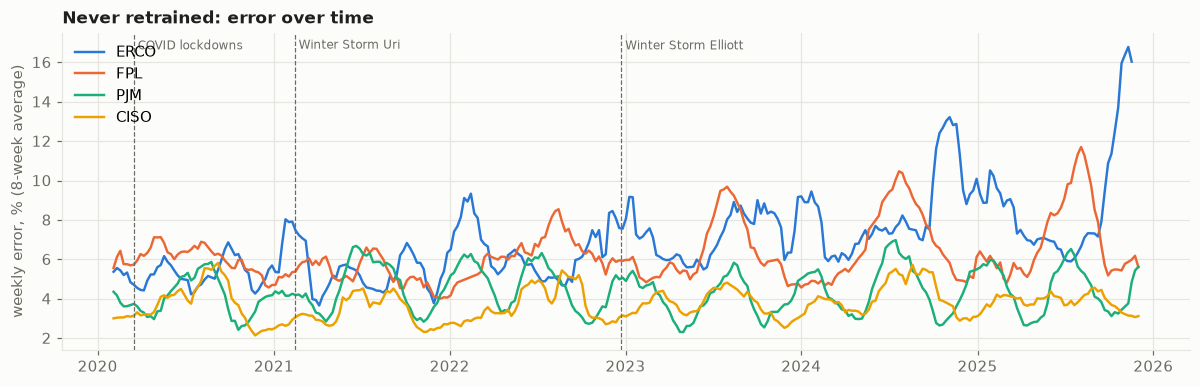

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.6))
for k, ba in enumerate(['ERCO', 'FPL', 'PJM', 'CISO']):
    s = pd.Series(never[ba]['mae'], index=pd.to_datetime(never[ba]['weeks'])) * 100
    ax.plot(s.rolling(8, center=True).mean(), color=plot.SERIES[k], label=ba)
for name, day in eia.EVENTS.items():
    ax.axvline(pd.Timestamp(day), color=plot.MUTED, linewidth=0.8, linestyle='--')
    ax.text(pd.Timestamp(day), ax.get_ylim()[1] * 0.98, ' ' + name, fontsize=8, color=plot.MUTED, va='top')
ax.set_ylabel('weekly error, % (8-week average)'); ax.set_title('Never retrained: error over time')
ax.legend(loc='upper left'); plt.tight_layout()

## 1 · Input-drift alarms on weather-driven data

The usual rule is "PSI above 0.2 means significant drift". Here are the actual PSI levels on ordinary weeks:

In [4]:
raw = eia.load_raw(); lv = {}
for ba in ('PJM', 'ERCO'):
    s = eia.stream(ba, raw); st = backtest.initial(s)
    weekly = [backtest.score('psi', st, s, b, None, {}, 1) for b in range(60, len(s.X))]
    seasonal = [backtest.score('psi_seasonal', st, s, b, None, {}, 1) for b in range(60, len(s.X))]
    lv[ba] = {'1 week vs training year: median': np.median(weekly), '4 weeks vs same weeks last year: median': np.median(seasonal),
              '4 weeks vs same weeks last year: 10th pct': np.percentile(seasonal, 10)}
pd.DataFrame(lv).round(2)

,PJM,ERCO
1 week vs training year: median,5.83,6.10
4 weeks vs same weeks last year: median,1.13,1.86
4 weeks vs same weeks last year: 10th pct,0.27,0.34


Two reasons the numbers are so far above 0.2:

1. **Too few distinct values.** Several features are daily (yesterday's mean and peak): a week holds only
   7 of them, which cannot fill 10 bins, and every empty bin adds a large fixed amount to PSI.
2. **Weather.** Even comparing 4 weeks with the same 4 weeks a year earlier (5 bins), a hot spell or a
   mild winter shifts the whole demand distribution far more than slow drift does.

So input-drift alarms either fire every week or, set high enough to stay quiet, never fire:

In [5]:
ps = t[(t.trigger == 'psi_seasonal') & (t.period == 'test')].groupby('threshold').agg(
    error_pct=('error_mean', lambda x: 100 * x.mean()), retrains_per_operator=('retrains', 'mean'))
ps.round(2)

,error_pct,retrains_per_operator
threshold,,
0.5,5.09,44.67
1.0,5.09,36.33
2.0,5.08,24.58
4.0,5.11,6.33
8.0,5.42,0.00


## 2 · Which trigger, chosen on 2020-21, does best on 2022-25?

Price of a retrain = k weeks of the operator's normal forecast error. Savings are against never
retraining, summed over the 12 operators, with a 95% interval from resampling operators.

In [6]:
sv = json.load(open('results/real_vs_never.json'))
tab = pd.DataFrame({f'retrain = {k} wk': {trig: f"{v['saving_vs_never']:+.1f}  [{v['ci95'][0]:+.1f}, {v['ci95'][1]:+.1f}]"
                                           for trig, v in res.items()} for k, res in sv.items()})
tab.loc[['schedule', 'error', 'page_hinkley', 'error_cp', 'page_hinkley_cp', 'c2st', 'psi_seasonal', 'ks', 'pred_psi', 'psi']]

,retrain = 1 wk,retrain = 4 wk,retrain = 16 wk
schedule,"+6.5 [+1.2, +14.4]","+2.7 [-3.0, +10.7]","-12.6 [-20.0, -3.5]"
error,"+3.8 [+0.2, +9.4]","+2.1 [-0.0, +6.4]","+1.6 [-0.0, +4.7]"
page_hinkley,"+3.9 [+0.0, +9.9]","+2.7 [+0.1, +6.9]","-0.1 [-3.1, +3.7]"
error_cp,"+2.3 [-0.0, +6.8]","+2.1 [-0.0, +6.4]","+1.6 [-0.0, +4.7]"
page_hinkley_cp,"+3.4 [+0.6, +8.0]","+2.7 [+0.1, +7.0]","-0.1 [-3.1, +3.6]"
c2st,"+4.5 [-1.3, +12.9]","+1.6 [-4.3, +9.2]","-9.9 [-19.1, -2.3]"
psi_seasonal,"-0.0 [-0.0, -0.0]","-0.0 [-0.0, -0.0]","-0.0 [-0.0, -0.0]"
ks,"-0.0 [-0.0, -0.0]","-0.0 [-0.0, -0.0]","-0.0 [-0.0, -0.0]"
pred_psi,"-2.7 [-10.2, +7.0]","-35.5 [-47.9, -22.7]","-166.6 [-205.3, -127.5]"
psi,"-24.9 [-35.4, -12.9]","-123.4 [-150.4, -98.2]","-517.2 [-614.2, -426.0]"


In [7]:
pick = {k: realdata.choose_and_score(t, k).set_index('trigger').threshold for k in realdata.RETRAIN_WEEKS}
pd.DataFrame(pick).rename(columns=lambda k: f'threshold chosen, {k} wk')

,"threshold chosen, 1 wk","threshold chosen, 4 wk","threshold chosen, 16 wk"
trigger,,,
c2st,0.99,0.99,0.99
error,2.00,3.00,3.00
error_cp,3.00,3.00,3.00
error_cpw,2.00,3.00,3.00
ks,300.00,300.00,300.00
never,NaN,NaN,NaN
page_hinkley,8.00,16.00,16.00
page_hinkley_cp,16.00,16.00,16.00
page_hinkley_cpw,8.00,16.00,16.00


**Reading it:**

- **Total cost of never retraining is 133.7**, so the best savings are 2-5%. On this task most models
  hold up; retraining pays mainly where demand **grew** (ERCOT, Florida).
- **Performance-based triggers save a little at low and medium retrain prices** and fire rarely
  (ERCOT once or twice). At the highest price the error ratio still saves slightly; Page-Hinkley breaks even.
- **A fixed schedule (every two years) wins when retrains are cheap and loses when they are expensive.**
- **Input-drift triggers:** weekly PSI and prediction PSI fire nearly every week and are very costly;
  seasonal PSI and the KS test, at the thresholds chosen, never fire at all; the classifier test at its
  strictest setting is roughly break-even.
- The chosen thresholds sit at the quiet end of every grid: the tuning period saying "retraining didn't
  pay in 2020-21". That made them slightly too timid for 2022-25, when growth arrived.

## 3 · The change-point trick does not transfer

On the synthetic streams, retraining only on data after the estimated change was the best idea. On
seasonal demand it backfires badly: a few weeks of post-change data lose the yearly cycle, and error
jumps from 4-7% to 6-26%. Page-Hinkley at threshold 1.0, test years:

In [8]:
cp = t[(t.period == 'test') & t.trigger.isin(['page_hinkley', 'page_hinkley_cp']) & (t.threshold == 1.0)]
(cp.pivot(index='ba', columns='trigger', values='error_mean') * 100).round(2)

trigger,page_hinkley,page_hinkley_cp
ba,,
BPAT,3.94,9.36
CISO,3.65,13.25
DUK,6.76,11.68
ERCO,6.00,15.84
FPL,5.98,10.36
ISNE,6.26,13.69
MISO,3.66,6.84
NYIS,4.79,8.63
PJM,4.70,12.55


A compromise keeps a **full year** of training data and weights the post-change weeks 4 times. That
removes the failure (Page-Hinkley at 1.0: 5.33% instead of 12.98%), but it doesn't beat the plain
triggers, and in the simulation it gave the change-point benefit back. No free lunch.

In [9]:
w = t[(t.period == 'test') & t.trigger.isin(['page_hinkley', 'page_hinkley_cp', 'page_hinkley_cpw'])]
(w.groupby(['threshold', 'trigger']).error_mean.mean().unstack() * 100).round(2)

trigger,page_hinkley,page_hinkley_cp,page_hinkley_cpw
threshold,,,
0.5,5.13,11.63,5.24
1.0,5.20,12.98,5.33
2.0,5.23,9.45,5.26
4.0,5.25,6.43,5.29
8.0,5.26,5.65,5.27
16.0,5.27,5.27,5.27


## 4 · One threshold for everyone, or one per operator?

Each operator could get the threshold that worked best for *it* in 2020-21. Total test cost, retrain = 4 weeks:

In [10]:
po = pd.read_csv('results/real_per_operator.csv', index_col=0)
po[po.k == 4][['shared', 'per-operator']].round(2).sort_values('shared')

,shared,per-operator
trigger,,
page_hinkley,131.01,131.26
page_hinkley_cp,131.01,201.76
page_hinkley_cpw,131.03,131.51
schedule,131.03,131.03
error_cpw,131.62,132.39
error_cp,131.62,188.46
error,131.62,131.64
c2st,132.10,132.10
ks,133.74,133.74


Per-operator thresholds are never clearly better and sometimes far worse: two years of one operator's
history is too little to tune on. **Pooling across operators is the more robust choice.**

## 5 · A stronger model: add weather

The forecaster above has no weather, which no real operator would accept. Adding hourly temperature
(Open-Meteo historical archive, one representative city per operator, used as a *perfect* next-day
forecast) cuts its error substantially, so how does it drift?

In [11]:
wrows = json.load(open('results/real_runs_weather.json'))
wt = realdata.table(wrows)
wnever = {r['ba']: r for r in wrows if r['trigger'] == 'never'}
wyr = pd.DataFrame({ba: pd.Series(r['mae'], index=pd.to_datetime(r['weeks'])).groupby(lambda x: x.year).mean()
                    for ba, r in wnever.items()}).T
cmp = pd.DataFrame({'no weather 2020': yr[2020], 'no weather 2025': yr[2025],
                    'weather 2020': wyr[2020], 'weather 2025': wyr[2025]}) * 100
cmp.round(1)

,no weather 2020,no weather 2025,weather 2020,weather 2025
ERCO,5.2,9.3,3.4,14.3
PJM,4.1,4.7,3.2,3.9
CISO,3.7,3.8,3.5,3.7
MISO,3.2,3.5,2.8,2.8
SWPP,4.3,5.4,3.7,6.2
NYIS,4.6,5.2,3.3,4.2
ISNE,5.9,7.2,4.7,5.7
SOCO,5.5,5.7,3.1,3.4
TVA,5.8,6.9,3.3,4.7
BPAT,3.4,3.6,2.6,4.1


**The better model is more fragile.** With weather, ERCOT starts at 3.4% error (vs 5.2%) but reaches
14.3% by 2025 (vs 9.3%): it leans on the temperature-to-demand relationship, and growth changes exactly
that. Florida shows the same pattern. So retraining matters more:

In [12]:
wsv = json.load(open('results/real_vs_never_weather.json'))
total = wt[(wt.period == 'test') & (wt.trigger == 'never')].error_sum.sum()
print(f'never retrain, total test cost: {total:.1f}')
pd.DataFrame({f'retrain = {k} wk': {trig: f"{v['saving_vs_never']:+.1f}  [{v['ci95'][0]:+.1f}, {v['ci95'][1]:+.1f}]"
                                     for trig, v in res.items()} for k, res in wsv.items()})

never retrain, total test cost: 113.7


,retrain = 1 wk,retrain = 4 wk,retrain = 16 wk
c2st,"+19.0 [+4.3, +41.2]","+15.9 [+1.8, +37.2]","+3.2 [-10.4, +22.4]"
error,"+5.3 [-0.0, +12.3]","+5.2 [-0.0, +12.1]","+4.4 [-0.0, +10.9]"
error_cpw,"+7.0 [-0.0, +15.9]","+6.7 [-0.0, +15.4]","+5.7 [-0.0, +13.5]"
page_hinkley,"+12.9 [+1.2, +30.8]","+12.3 [+0.8, +30.1]","+10.2 [-0.9, +27.2]"
page_hinkley_cpw,"+12.7 [+1.0, +31.2]","+12.1 [+0.7, +30.4]","+9.6 [-1.2, +26.8]"
psi_seasonal,"-0.0 [-0.0, -0.0]","-0.0 [-0.0, -0.0]","-0.0 [-0.0, -0.0]"
schedule,"+17.5 [+4.1, +37.5]","+14.9 [+1.4, +35.0]","+4.5 [-9.4, +25.4]"


**Without the perfect-forecast assumption:** the same model served the *archived day-ahead forecast*
(what was actually available the day before, from mid-2021) in the test years:

In [13]:
fsv = json.load(open('results/real_vs_never_weather_forecast.json'))
pd.DataFrame({f'retrain = {k} wk': {trig: f"{v['saving_vs_never']:+.1f}  [{v['ci95'][0]:+.1f}, {v['ci95'][1]:+.1f}]"
                                     for trig, v in res.items()} for k, res in fsv.items()})

,retrain = 1 wk,retrain = 4 wk,retrain = 16 wk
c2st,"+18.4 [+2.8, +41.1]","+15.2 [+0.1, +37.3]","+2.8 [-12.0, +23.2]"
error,"+6.1 [-0.0, +14.1]","+6.0 [-0.0, +13.8]","+5.2 [-0.0, +12.7]"
error_cpw,"+5.7 [-0.0, +13.1]","+5.5 [-0.0, +12.6]","+4.8 [-0.0, +11.3]"
page_hinkley,"+13.4 [+1.6, +29.7]","+12.7 [+1.1, +28.6]","+9.9 [-1.2, +25.0]"
page_hinkley_cpw,"+13.5 [+1.5, +31.2]","+12.8 [+1.0, +30.5]","+10.3 [-1.3, +27.3]"
psi_seasonal,"-0.0 [-0.0, -0.0]","-0.0 [-0.0, -0.0]","-0.0 [-0.0, -0.0]"
schedule,"+16.1 [+1.8, +36.5]","+13.6 [-1.0, +34.0]","+3.1 [-11.9, +24.4]"


Never retraining costs about 5% more with real forecasts (119.2 vs 113.7), and the ranking is unchanged.

- Savings rise to **14-17%** of total error at low and medium retrain prices (from 2-5% without weather).
- The best trigger here is an **input-drift** one: the classifier two-sample test at its strictest setting
  (AUC > 0.99), retraining about 2.5 times per operator. A classifier looking at all inputs together
  notices that the *combination* of temperature and demand has moved, which the model depends on. Simple
  PSI, even season-matched, still never fires usefully.
- A two-year schedule is a close second; at a high retrain price Page-Hinkley is best, but its interval
  includes zero.

So the simulation's verdict ("input drift is never the best signal") holds for the simple model, not for
the stronger one. **Which signal to page on depends on the model as much as on the data.**

## 6 · When did each trigger retrain ERCOT? (no-weather model)

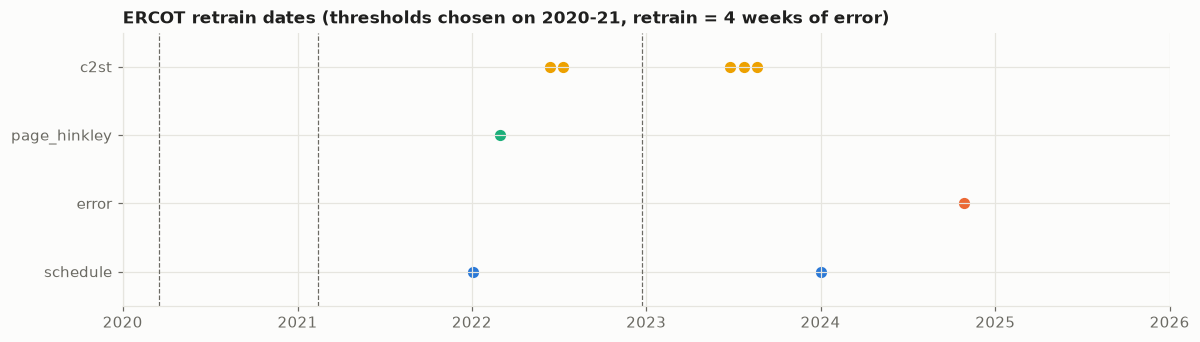

In [14]:
chosen = realdata.choose_and_score(t, 4).set_index('trigger').threshold
fig, ax = plt.subplots(figsize=(11, 3.2))
names = ['schedule', 'error', 'page_hinkley', 'c2st']
for k, trig in enumerate(names):
    r = next(r for r in rows if r['ba'] == 'ERCO' and r['trigger'] == trig and r['threshold'] == chosen[trig])
    ax.scatter(pd.to_datetime(r['retrains']), [k] * len(r['retrains']), s=40, color=plot.SERIES[k])
ax.set_yticks(range(len(names))); ax.set_yticklabels(names); ax.set_ylim(-0.5, len(names) - 0.5)
ax.set_xlim(pd.Timestamp('2020-01-01'), pd.Timestamp('2026-01-01'))
for name, day in eia.EVENTS.items():
    ax.axvline(pd.Timestamp(day), color=plot.MUTED, linewidth=0.8, linestyle='--')
ax.set_title('ERCOT retrain dates (thresholds chosen on 2020-21, retrain = 4 weeks of error)')
plt.tight_layout()

## What this shows

- On real, weather-driven data, **PSI as usually configured is noise**: it sits at 4-7 on ordinary
  weeks. A multivariate check (a classifier telling old data from new) at a strict threshold is a
  different matter: with the weather model it was the best trigger.
- **Performance triggers are the safe default** when labels come back quickly: they fire rarely and
  save something at most retrain prices.
- **A stronger model can be more fragile**, and then retraining is worth 14-17% instead of 2-5%.
- **Retraining is worth most where the world grows past the training range** (ERCOT); a tree model can't
  extrapolate, so growth is the drift that matters for this kind of model.
- Ideas that win in simulation (change-point windows) need checking against the real data's structure
  (here, seasonality).